In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [147]:
%pip -q install ISLP

In [148]:
from ISLP import load_data
carseats = load_data('Carseats')

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [149]:
#categories (High = 1, Low = 0)
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

#Check the number of stores in each category.
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


In [150]:
carseats.head()

,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,HighSales
0,138,73,11,276,120,Bad,42,17,Yes,Yes,1
1,111,48,16,260,83,Good,65,10,Yes,Yes,1
2,113,35,10,269,80,Medium,59,12,Yes,Yes,1
3,117,100,4,466,97,Medium,55,14,Yes,Yes,0
4,141,64,3,340,128,Bad,38,13,Yes,No,0


In [151]:
X = pd.get_dummies(carseats.drop(columns='HighSales')).astype(int)
y = carseats['HighSales']



In [152]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=9, stratify=y)

print(X_train.shape, X_test.shape)

X_train.head()

(280, 14) (120, 14)


,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
272,113,33,0,14,63,38,12,0,1,0,0,1,1,0
28,103,74,0,359,97,55,11,1,0,0,0,1,0,1
194,112,98,18,481,128,45,11,0,0,1,0,1,0,1
162,122,74,0,424,149,51,13,0,0,1,0,1,1,0
141,140,42,0,331,131,28,15,1,0,0,0,1,1,0


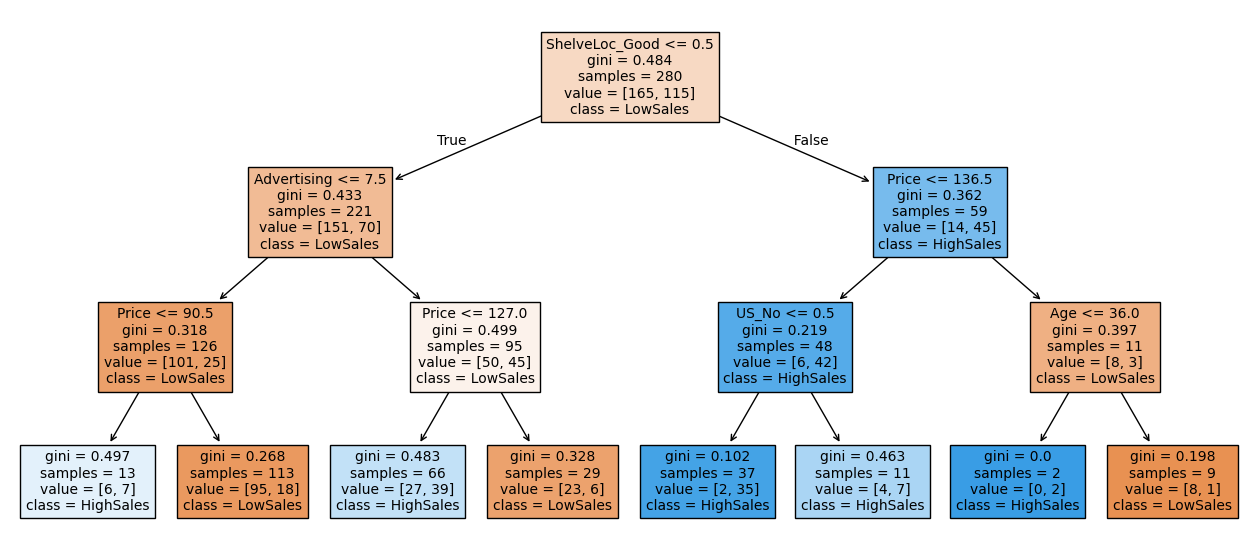

Train accuracy: 0.771
Test accuracy:  0.817


In [153]:
tree1 = DecisionTreeClassifier(max_depth=3, random_state=9)
tree1.fit(X_train, y_train)

plt.figure(figsize=(16, 7))

plot_tree(tree1,
          feature_names=list(X.columns),
          class_names=['LowSales', 'HighSales'],
          filled=True,
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree1.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree1.score(X_test, y_test), 3))

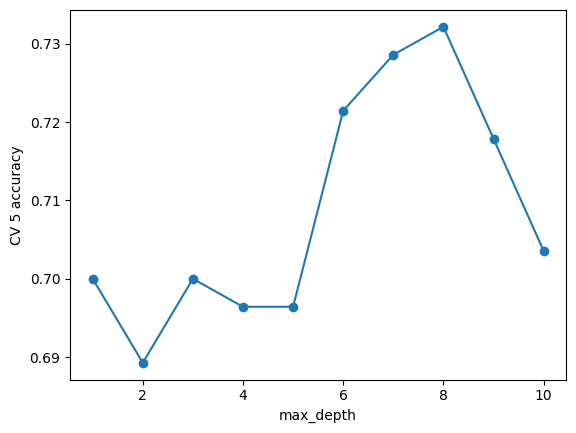

BestDepth 8
Best acc 0.732


In [154]:

depths = range(1, 11)
cv_acc = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=9)
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=5).mean())

plt.plot(depths, cv_acc, marker='o')
plt.xlabel('max_depth'); plt.ylabel('CV 5 accuracy'); plt.show()

best_depth = list(depths)[int(np.argmax(cv_acc))]


print('BestDepth', best_depth)

print('Best acc', round(max(cv_acc), 3))

In [159]:
finaltree = DecisionTreeClassifier(max_depth=best_depth, random_state=9)
finaltree.fit(X_train, y_train)

print('Test accuracy:',round(finaltree.score(X_test, y_test), 3))


Test accuracy: 0.783


1. Interpreting the tree: Which predictor was selected for the first split (root)? What does this split tell us about sales?

ShelveLoc_Good and it tells that a good point to begin for predicting sales shelveloc

2. Choosing tree depth: According to your cross-validation graph, which depth performed best? Why should we use cross-validation rather than test accuracy to choose the depth?

depth 8, and cross validation would give a better depth because it is compares depths in 5 folds and gives the average.

3. Overfitting: Does increasing tree depth always improve cross-validation accuracy?
Explain using your graph

No increasing tree depth dose not always improve cross validation accuracy and this can be seen in the graph, for example after a max depth of 8, cross validation accuracy goes down.